# Data Science w Pythonie — Zajęcia 6

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kubzal/wsb-merito/blob/main/notebooks/semestr_zimowy_2026_27/data_science_w_pythonie/zajecia_6.ipynb)

Pełne notatki do zajęć znajdziesz na [stronie przedmiotu](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/data_science_w_pythonie/zajecia_6/). Ten notebook zawiera wszystkie przykłady z notatek, gotowe do uruchomienia.


## Mini-projekt — od pytania do raportu

Przez pięć zajęć poznawałeś narzędzia jedno po drugim: wczytywanie,
czyszczenie, wykresy, grupowanie, łączenie, budowanie cech. Każde zadanie
ćwiczyło jedno z nich. W pracy nikt nie powie Ci, którego narzędzia użyć —
dostaniesz pytanie, kilka plików i termin. Dziś robimy dokładnie to:
**mini-projekt analityczny** od pytania do raportu, z nowymi danymi, których
jeszcze nie widziałeś.

Nowych funkcji prawie nie będzie. Nowe jest to, **w jakiej kolejności** i **po
co** sięgasz po te, które znasz — i jak na końcu zamienić tabelki w kilka zdań,
które przeczyta ktoś, kto nie zna Pythona.

Po dzisiejszych zajęciach będziesz w stanie:

- zamienić ogólne pytanie biznesowe na pytanie, na które da się odpowiedzieć
  liczbami,
- przeprowadzić diagnozę nowego zbioru i zaplanować czyszczenie,
- połączyć kroki z poprzednich zajęć w jeden uporządkowany notatnik,
- odróżnić wynik, który odpowiada na pytanie, od wyniku, który tylko jest
  ciekawy,
- napisać krótki raport z wnioskami, liczbami, rekomendacją i ograniczeniami.

> ℹ️ **Gdzie jesteśmy**
>
> Dziś cały workflow z pierwszych zajęć naraz: pytanie, dane, czyszczenie,
> eksploracja, komunikacja. Pomijamy tylko modelowanie — to za godzinę na
> [Uczeniu głębokim](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/uczenie_glebokie/zajecia_6/), gdzie na tych samych
> danych zbudujesz sieć przewidującą czas dostawy.


## Plan na dziś

| Blok | Czas |
|---|---|
| Jak wygląda mini-projekt | 5 min |
| Pytanie i diagnoza danych | 8 min |
| Czyszczenie i łączenie | 8 min |
| Cechy i analiza | 12 min |
| Wnioski i raport | 7 min |
| Ściągawka | 3 min |
| **Zadanie 6** | **45 min** |


## Jak wygląda mini-projekt

### Nowa firma: MeritoEats

**MeritoEats** to platforma dostaw jedzenia w Warszawie. Klient zamawia
w aplikacji, aplikacja pokazuje mu **obiecany czas dostawy**, restauracja
gotuje, kurier wiezie. Po wszystkim klient może (ale nie musi) wystawić ocenę
od 1 do 5. Średnia ocena spada od tygodni i dyrektor operacyjny chce wiedzieć
dlaczego.

Mamy dwa pliki z października: dziennik zamówień i słownik restauracji.

### Notatnik jako raport

Notatnik z projektu czyta potem ktoś inny — prowadzący, szef, Ty sam za
miesiąc. Dlatego układasz go w stałe sekcje, każdą z nagłówkiem w komórce
tekstowej:

| Sekcja | Co w niej jest | Narzędzia z zajęć |
|---|---|---|
| **1. Pytanie** | jedno–dwa zdania: co chcemy wiedzieć i po co | — |
| **2. Dane** | skąd są, ile wierszy, co znaczą kolumny, diagnoza | 1, 2 |
| **3. Czyszczenie** | co poprawiasz i **dlaczego** — z liczbą usuniętych wierszy | 2 |
| **4. Łączenie i cechy** | jakie tabele, jakie nowe kolumny | 4, 5 |
| **5. Analiza** | tabele i wykresy, które odpowiadają na pytanie | 3, 4 |
| **6. Wnioski** | odpowiedź, liczby, rekomendacja, ograniczenia | — |

Najważniejsza zasada: **każda komórka z kodem ma służyć odpowiedzi na
pytanie**. Jeśli nie wiesz, po co liczysz jakąś tabelę, nie liczysz jej.


## Pytanie i diagnoza danych

### Z ogólnego pytania — mierzalne

„Dlaczego klienci są niezadowoleni?" to dobre pytanie dla dyrektora, ale
złe dla analityka: nie wiadomo, co policzyć. Zamieniamy je na pytanie, na które
odpowie tabela:

> **Od czego zależy ocena zamówienia — od długości dostawy, odległości,
> wartości zamówienia czy od tego, czy dotrzymaliśmy obietnicy?**

Teraz wiadomo, czego szukać: kolumny `ocena` i jej związku z kilkoma innymi.

### Diagnoza

Zanim cokolwiek policzysz, sprawdzasz, co dostałeś — dokładnie tak jak na
zajęciach 2:

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

URL_PAZ = "https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/data_science_w_pythonie/dane/zamowienia_pazdziernik_2026.csv"
URL_REST = "https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/data_science_w_pythonie/dane/restauracje_2026.csv"

zam = pd.read_csv(URL_PAZ)
print(zam.shape)
zam.head(3)

(1851, 11)


,zamowienie_id,data_godzina,restauracja_id,dzielnica,odleglosc_km,liczba_pozycji,wartosc_zl,pogoda,obiecany_czas_min,czas_dostawy_min,ocena
0,Z00001,2026-10-01 10:03,R15,Mokotów,2.2,1,39.23,sucho,35,29,NaN
1,Z00002,2026-10-01 10:08,R17,ŚRÓDMIEŚCIE,2.2,4,96.37,sucho,35,25,NaN
2,Z00003,2026-10-01 10:12,R27,Mokotów,2.0,4,174.74,sucho,30,26,4.0


In [2]:
print("duplikaty:", zam.duplicated().sum())
print()
print(zam.isna().sum())

duplikaty: 21

zamowienie_id           0
data_godzina            0
restauracja_id          0
dzielnica               0
odleglosc_km            0
liczba_pozycji          0
wartosc_zl              0
pogoda                  0
obiecany_czas_min       0
czas_dostawy_min        0
ocena                1035
dtype: int64


In [3]:
print("różnych dzielnic:", zam["dzielnica"].nunique())
zam["czas_dostawy_min"].describe().round(1)

różnych dzielnic: 40


count    1851.0
mean       39.3
std        54.2
min       -12.0
25%        29.0
50%        36.0
75%        44.0
max      1440.0
Name: czas_dostawy_min, dtype: float64

Trzy problemy i jeden fałszywy alarm:

- **duplikaty** — kilkadziesiąt zamówień zapisanych dwa razy,
- **dzielnice** — MeritoEats działa w 8 dzielnicach, a różnych wartości jest
  40. To pisownia: `"ŚRÓDMIEŚCIE"`, `"Mokotów "` ze spacją,
- **czas dostawy** — minimum ujemne, maksimum 1440 minut, czyli równa doba.
  To błędy systemu, nie dostawy,
- **braki w ocenie** to **nie** błąd. Ponad połowa klientów po prostu nie
  wystawia ocen. Tych braków nie uzupełniamy — średnia z wymyślonych ocen nic
  nie znaczy. Liczymy na tych, którzy ocenili, i piszemy o tym w ograniczeniach.


## Czyszczenie i łączenie

### Czyszczenie z licznikiem

Przy każdym kroku zapisujesz, ile wierszy ubyło — w raporcie musisz umieć
powiedzieć, co wyrzuciłeś:

In [4]:
przed = len(zam)
zam = zam.drop_duplicates()
print("duplikaty:      ", przed - len(zam))

zam["dzielnica"] = zam["dzielnica"].str.strip().str.title()

przed = len(zam)
zam = zam[zam["czas_dostawy_min"].between(1, 300)]
print("błędne czasy:   ", przed - len(zam))

zam["data_godzina"] = pd.to_datetime(zam["data_godzina"])
print("zostało:        ", len(zam), "| dzielnic:", zam["dzielnica"].nunique())

duplikaty:       21
błędne czasy:    14
zostało:         1816 | dzielnic: 8


Próg 300 minut to decyzja, nie prawda objawiona — dostawa trwająca 5 godzin
też byłaby podejrzana, ale żadnej takiej nie ma: wartości są albo do ok. 90
minut, albo absurdalne (455, 720, 1440). Taką decyzję zapisujesz w komórce
tekstowej jednym zdaniem.

### Łączenie ze słownikiem restauracji

In [5]:
rest = pd.read_csv(URL_REST)
print(rest.shape)

przed = len(zam)
zam = zam.merge(rest, on="restauracja_id", how="left")
print(przed, "→", len(zam))
print("bez kuchni:", zam["kuchnia"].isna().sum(), "| restauracja:",
      zam.loc[zam["kuchnia"].isna(), "restauracja_id"].unique().tolist())

(34, 4)
1816 → 1816
bez kuchni: 70 | restauracja: ['R17']


Liczba wierszy się zgadza, ale jedna restauracja — `R17` — nie ma wpisu
w słowniku (dział partnerów wyjaśnia: zakończyła współpracę i ktoś ją
usunął). Jej zamówienia są prawdziwe, więc ich nie wyrzucamy — oznaczamy
kuchnię jako nieznaną:

In [6]:
zam["kuchnia"] = zam["kuchnia"].fillna("nieznana")

## Cechy i analiza

### Cechy, które odpowiadają na pytanie

Pytanie dotyczyło m.in. **dotrzymania obietnicy**, a takiej kolumny nie ma.
Budujemy ją jak na zajęciach 5:

In [7]:
zam["godzina"] = zam["data_godzina"].dt.hour
zam["spoznienie_min"] = zam["czas_dostawy_min"] - zam["obiecany_czas_min"]
zam["spoznione"] = (zam["spoznienie_min"] > 5).astype(int)

zam[["obiecany_czas_min", "czas_dostawy_min", "spoznienie_min", "spoznione"]].head(3)

,obiecany_czas_min,czas_dostawy_min,spoznienie_min,spoznione
0,35,29,-6,0
1,35,25,-10,0
2,30,26,-4,0


`spoznienie_min` ujemne oznacza, że jedzenie przyjechało **przed** czasem.
Za spóźnione uznajemy zamówienia ponad 5 minut po obietnicy — kilka minut
klient wybacza. To znowu decyzja, którą zapisujesz.

### Co wiąże się z oceną

In [8]:
print("ocenionych zamówień:", zam["ocena"].notna().sum(), "z", len(zam))

zam[["czas_dostawy_min", "odleglosc_km", "wartosc_zl", "spoznienie_min"]].corrwith(zam["ocena"]).round(3)

ocenionych zamówień: 797 z 1816


czas_dostawy_min   -0.536
odleglosc_km       -0.096
wartosc_zl         -0.115
spoznienie_min     -0.714
dtype: float64

`corrwith` sam pomija braki — liczy tylko na zamówieniach z oceną.
Najmocniej z oceną wiąże się spóźnienie (−0.71), ale czas dostawy też całkiem
mocno (−0.54). Czy to dwa różne powody, czy jeden? Spóźnione zamówienia są
przecież zwykle też długie. Zobaczmy ocenę w przedziałach spóźnienia:

In [9]:
przedzialy = pd.cut(zam["spoznienie_min"], bins=[-60, 0, 5, 10, 20, 60])
zam.groupby(przedzialy, observed=True)["ocena"].agg(["count", "mean"]).round(2)

,count,mean
spoznienie_min,,
"(-60, 0]",300,4.49
"(0, 5]",189,4.16
"(5, 10]",145,3.54
"(10, 20]",152,2.93
"(20, 60]",11,1.64


Text(0, 0.5, 'średnia ocena (1–5)')

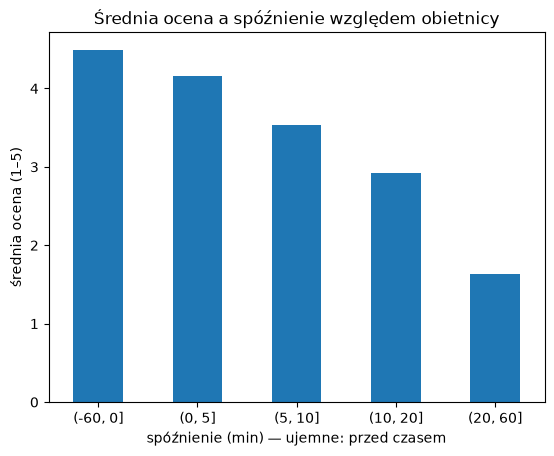

In [10]:
zam.groupby(przedzialy, observed=True)["ocena"].mean().plot(
    kind="bar", title="Średnia ocena a spóźnienie względem obietnicy")
plt.xticks(rotation=0)
plt.xlabel("spóźnienie (min) — ujemne: przed czasem")
plt.ylabel("średnia ocena (1–5)")

Dopóki obietnica jest dotrzymana, ocena trzyma się ok. 4.5. Każde kolejne
minuty spóźnienia kosztują coraz więcej. Ostatni przedział to tylko 11 ocen —
kierunek jest jasny, ale liczby 1.64 nie warto cytować z dokładnością do
setnych. A teraz kluczowy test — **zamówienia
dowiezione na czas**, ale różnej długości:

In [11]:
na_czas = zam[zam["spoznienie_min"] <= 0]
na_czas.groupby(pd.cut(na_czas["czas_dostawy_min"], bins=[0, 30, 40, 60]),
                observed=True)["ocena"].agg(["count", "mean"]).round(2)

,count,mean
czas_dostawy_min,,
"(0, 30]",173,4.46
"(30, 40]",102,4.55
"(40, 60]",25,4.48


Ta sama ocena, niezależnie od tego, czy dostawa trwała 25 czy 45 minut. Klienci
nie karzą za **długą** dostawę, tylko za **niedotrzymaną obietnicę**. Korelacja
z czasem dostawy była „pożyczona" od spóźnień — długie dostawy częściej się
spóźniają.

### Skąd się biorą spóźnienia

Skoro problemem są spóźnienia, naturalne kolejne pytanie — kiedy się
zdarzają:

Text(0, 0.5, 'odsetek spóźnionych')

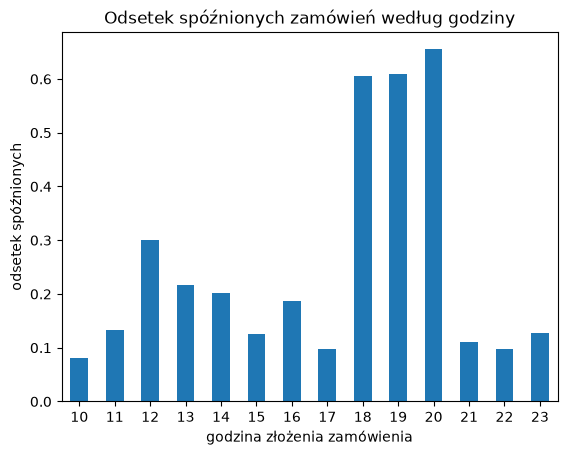

In [12]:
zam.groupby("godzina")["spoznione"].mean().plot(
    kind="bar", title="Odsetek spóźnionych zamówień według godziny")
plt.xticks(rotation=0)
plt.xlabel("godzina złożenia zamówienia")
plt.ylabel("odsetek spóźnionych")

W wieczornym szczycie (18–20) spóźnia się 6 zamówień na 10, w pozostałych
godzinach — najwyżej co trzecie, najczęściej co dziesiąte. Aplikacja obiecuje ten sam czas o 15:00 i o 19:00, choć
o 19:00 kuchnie i ulice są zapchane.

> ⚠️ **Ciekawe to nie to samo co ważne**
>
> W trakcie analizy znajdziesz mnóstwo rzeczy: że w weekendy zamawia się
> więcej, że sushi jest najdroższe, że Mokotów zamawia najczęściej. Jeśli to
> nie odpowiada na pytanie — nie trafia do wniosków. Raport z dwudziestoma
> ciekawostkami to raport, z którego nikt nic nie zapamięta.


## Wnioski i raport

### Pięć elementów dobrego wniosku

1. **Odpowiedź w pierwszym zdaniu.** Dyrektor może nie doczytać do końca.
2. **Liczby** — konkretne, zaokrąglone, z liczebnością, gdy grupa jest mała.
3. **Mechanizm** — co z czego wynika, jeśli to wiadomo.
4. **Rekomendacja** — co zrobić.
5. **Ograniczenia** — czego dane nie mówią.

Zamiast:

> Korelacja oceny ze `spoznienie_min` wynosi −0.714, a z `czas_dostawy_min`
> −0.536. Groupby po godzinie pokazał max 0.66 dla godziny 20.

piszesz:

> **Oceny spadają przez niedotrzymane obietnice, a nie przez długie dostawy.**
> Zamówienia dowiezione na czas mają średnią ocenę 4.5 niezależnie od tego,
> czy jechały 25, czy 45 minut. Już 5–10 minut spóźnienia obniża ocenę do 3.5,
> a 10–20 minut — do 2.9. Najwięcej spóźnień jest w wieczornym szczycie
> (18–20), gdy spóźnia się 6 zamówień na 10. **Rekomendacja:** w godzinach
> szczytu aplikacja powinna obiecywać dłuższy czas — klient chętniej poczeka
> 45 minut, jeśli tyle mu obiecano, niż 35, gdy obiecano 30.
> **Ograniczenia:** ocenia tylko 44% klientów, a dane obejmują jeden miesiąc.

Bez nazw kolumn, bez kodu, z jedną liczbą na każde twierdzenie.

> 📝 **Korelacja to nie przyczyna — ale tu mamy mechanizm**
>
> Sam wynik „spóźnione zamówienia mają gorsze oceny" mógłby mieć inne
> wyjaśnienie (np. spóźniają się konkretne restauracje, które gotują gorzej).
> Test z zamówieniami dowiezionymi na czas wzmacnia nasz wniosek, ale go nie
> dowodzi. Pewność dałby dopiero eksperyment: części klientów aplikacja
> obiecuje dłuższy czas, części — krótszy, i porównujemy oceny. Takie testy
> firmy robią na co dzień (*testy A/B*).


## Ściągawka

| Etap | Pytanie kontrolne | Kod |
|---|---|---|
| Pytanie | czy wiem, którą kolumnę i z czym porównać? | — |
| Diagnoza | ile wierszy, jakie typy, ile braków i duplikatów? | `df.shape`, `df.info()`, `df.isna().sum()`, `df.duplicated().sum()` |
| | czy tekst jest spójny? | `df["kol"].nunique()`, `df["kol"].value_counts()` |
| | czy liczby mają sens? | `df["kol"].describe()` |
| Czyszczenie | ile wierszy usunąłem i dlaczego? | `przed = len(df)` … `print(przed - len(df))` |
| | tekst | `df["kol"].str.strip().str.title()` |
| | wartości niemożliwe | `df[df["kol"].between(a, b)]` |
| | daty | `pd.to_datetime(df["data"])`, `format="%d.%m.%Y %H:%M"` |
| Wczytanie innego formatu | średniki, przecinki | `pd.read_csv(url, sep=";", decimal=",")` |
| | inna nazwa kolumny | `df.rename(columns={"stara": "nowa"})` |
| | dwa pliki jeden pod drugim | `pd.concat([t1, t2], ignore_index=True)` |
| Łączenie | czy liczba wierszy się zgadza? | `print(przed, "→", len(df))` |
| | czy coś nie znalazło pary? | `df["kol_z_prawej"].isna().sum()` |
| Cechy | czy potrzebuję kolumny, której nie ma? | różnica, iloraz, flaga, `dt.hour`, `dt.month` |
| Analiza | czy ta tabela odpowiada na pytanie? | `groupby(...).agg(...)`, `pd.cut`, `corrwith` |
| | czy grupa nie jest za mała? | `agg(["count", "mean"])` |
| Wnioski | odpowiedź — liczby — mechanizm — rekomendacja — ograniczenia | komórka tekstowa |

## Zadanie 6

Treść zadania na dzisiejsze zajęcia znajdziesz w [notatkach](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/data_science_w_pythonie/zajecia_6/#zadanie-6-dlaczego-jedzenie-sie-spoznia-6-pkt). Rozwiązanie zrób w **osobnym** notebooku i oddaj go na Moodle.